# Bank Customer Churn — Exploratory Data Analysis

**Objective:** reduce churn by identifying which customers are most likely to churn next.

**Target:** `Exited` (1 = the customer left the bank, 0 = still a customer).

Plan:

1. Inspect the raw data: dimensions, schema, target, missing values, duplicates.
2. Split into train/test with **stratified sampling** (the target is imbalanced).
3. Do the distributional EDA (outliers, categorical frequencies, numeric distributions)
   on the **training set only**, so the test set stays unseen until final evaluation.

## 0. Setup

In [63]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

%matplotlib inline
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# works whether the kernel runs from notebooks/ or from the project root
DATA_PATH = next(
    (p for p in (Path("../data/raw/Churn_Modelling.csv"),
                 Path("data/raw/Churn_Modelling.csv")) if p.exists()),
    None,
)
assert DATA_PATH is not None, "Churn_Modelling.csv not found under data/raw/"
df = pd.read_csv(DATA_PATH)

TARGET = "Exited"
ID_COLS = ["RowNumber", "CustomerId"]
DROP_COLS = ["RowNumber", "CustomerId", "Surname"]          # identifiers, no signal
BINARY_COLS = ["HasCrCard", "IsActiveMember"]
NUMERIC_COLS = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
CATEGORICAL_COLS = ["Geography", "Gender", "Surname"]
RANDOM_STATE = 42


def section(title: str) -> None:
    """Print a readable section header."""
    print(f"\n{'=' * 78}\n{title}\n{'=' * 78}")


print(f"loaded {df.shape[0]:,} rows x {df.shape[1]} columns from {DATA_PATH.resolve()}")
display(df.head())

loaded 10,000 rows x 14 columns from C:\Data Science Projects\Bank Churn Modelling\data\raw\Churn_Modelling.csv


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,"101,348.88",1
1,2,15647311,Hill,608,Spain,Female,41,1,"83,807.86",1,0,1,"112,542.58",0
2,3,15619304,Onio,502,France,Female,42,8,"159,660.80",3,1,0,"113,931.57",1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,"93,826.63",0
4,5,15737888,Mitchell,850,Spain,Female,43,2,"125,510.82",1,1,1,"79,084.10",0


## 1. Raw data inspection

### 1.1 Dimensions

In [51]:
section("1.1 DIMENSIONS")
print(f"rows (records): {df.shape[0]:,}")
print(f"columns       : {df.shape[1]}")
print(f"cells         : {df.size:,}")
print(f"memory        : {df.memory_usage(deep=True).sum() / 1024 ** 2:,.2f} MB")
print(f"unique CustomerIds in {df.shape[0]:,} rows: {df['CustomerId'].nunique():,}")


1.1 DIMENSIONS
rows (records): 10,000
columns       : 14
cells         : 140,000
memory        : 2.41 MB
unique CustomerIds in 10,000 rows: 10,000


### 1.2 Column names & data types

In [52]:
section("1.2 COLUMNS & DATA TYPES")
df.info()

schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "null": df.isna().sum(),
    "null_pct": df.isna().mean().mul(100).round(2),
    "n_unique": df.nunique(),
    "example": [df[c].dropna().iloc[0] if df[c].notna().any() else np.nan for c in df.columns],
})
print(schema)


1.2 COLUMNS & DATA TYPES
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB
                   dtype  non_null  null  null_pct  n_unique    example
RowNumber  

### 1.3 Target variable

In [53]:
section("1.3 TARGET VARIABLE")
print(f"target column : '{TARGET}'  (dtype={df[TARGET].dtype})")
print(f"unique values : {sorted(df[TARGET].dropna().unique().tolist())}")

target_counts = df[TARGET].value_counts().sort_index()
print(pd.DataFrame({
    "count": target_counts,
    "share_%": (target_counts / len(df) * 100).round(2),
}).rename(index={0: "0 = stayed", 1: "1 = churned"}))
print(f"\nchurn rate: {df[TARGET].mean():.2%}  ->  "
      f"{(df[TARGET] == 0).sum() / (df[TARGET] == 1).sum():.2f} stays per churn")


1.3 TARGET VARIABLE
target column : 'Exited'  (dtype=int64)
unique values : [0, 1]
             count  share_%
Exited                     
0 = stayed    7963    79.63
1 = churned   2037    20.37

churn rate: 20.37%  ->  3.91 stays per churn


### 1.4 Missing values

In [54]:
section("1.4 MISSING VALUES")
missing = pd.DataFrame({
    "null": df.isna().sum(),
    "null_pct": df.isna().mean().mul(100).round(2),
}).sort_values("null", ascending=False)
print(missing)

total_missing = int(df.isna().sum().sum())
print(f"\ntotal missing cells: {total_missing} ({total_missing / df.size:.4%} of {df.size:,})")
print("columns with missing values:", missing.query("null > 0").index.tolist() or "none")


1.4 MISSING VALUES
                 null  null_pct
RowNumber           0      0.00
CustomerId          0      0.00
Surname             0      0.00
CreditScore         0      0.00
Geography           0      0.00
Gender              0      0.00
Age                 0      0.00
Tenure              0      0.00
Balance             0      0.00
NumOfProducts       0      0.00
HasCrCard           0      0.00
IsActiveMember      0      0.00
EstimatedSalary     0      0.00
Exited              0      0.00

total missing cells: 0 (0.0000% of 140,000)
columns with missing values: none


### 1.5 Duplicate records

In [55]:
section("1.5 DUPLICATE RECORDS")
business_cols = [c for c in df.columns if c not in DROP_COLS]

print(f"exact duplicate rows (all columns)                   : {int(df.duplicated().sum())}")
print(f"duplicate rows on {ID_COLS}                  : {int(df.duplicated(subset=ID_COLS).sum())}")
print(f"duplicate rows ignoring RowNumber/CustomerId/Surname : {int(df.duplicated(subset=business_cols).sum())}")
print(f"RowNumber unique and gapless 1..n                    : "
      f"{df['RowNumber'].is_monotonic_increasing and df['RowNumber'].is_unique}")
print(f"repeated Surnames (expected, not duplicates)         : "
      f"{int(df['Surname'].duplicated().sum()):,} of {len(df):,}")


1.5 DUPLICATE RECORDS
exact duplicate rows (all columns)                   : 0
duplicate rows on ['RowNumber', 'CustomerId']                  : 0
duplicate rows ignoring RowNumber/CustomerId/Surname : 0
RowNumber unique and gapless 1..n                    : True
repeated Surnames (expected, not duplicates)         : 7,068 of 10,000


### 1.6 Uniqueness, constants & identifier columns

In [56]:
section("1.6 UNIQUENESS, CONSTANTS & IDENTIFIERS")
print(f"all-unique columns (candidate ids): {df.columns[df.nunique() == len(df)].tolist()}")
print(f"constant columns (zero variance)  : {df.columns[df.nunique() == 1].tolist() or 'none'}")
print(f"dropped before modelling          : {DROP_COLS}")
print(f"\nbinary columns: {BINARY_COLS}")
print(df[BINARY_COLS].mean().mul(100).round(2).rename("share_of_1_%").to_string())
print(f"\ntarget: {TARGET} = {sorted(df[TARGET].unique().tolist())}")


1.6 UNIQUENESS, CONSTANTS & IDENTIFIERS
all-unique columns (candidate ids): ['RowNumber', 'CustomerId']
constant columns (zero variance)  : none
dropped before modelling          : ['RowNumber', 'CustomerId', 'Surname']

binary columns: ['HasCrCard', 'IsActiveMember']
HasCrCard        70.55
IsActiveMember   51.51

target: Exited = [0, 1]


## 2. Stratified split, then EDA on the training set

The target is imbalanced (~20% churn), so the split is **stratified**: both parts keep the
same churn rate. Everything below is computed on `train` only — the test set is left
untouched until final model evaluation.

### 2.1 Stratified train/test split

In [57]:
section("2.1 STRATIFIED TRAIN/TEST SPLIT")
X = df.drop(columns=[TARGET] + DROP_COLS)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

train = X_train.assign(**{TARGET: y_train})   # features + target, training rows only
test = X_test.assign(**{TARGET: y_test})      # kept aside for final evaluation

split_summary = pd.DataFrame({
    "rows": [len(df), len(y_train), len(y_test)],
    "share_%": [100.0, round(len(y_train) / len(y) * 100, 2), round(len(y_test) / len(y) * 100, 2)],
    "churned": [int(y.sum()), int(y_train.sum()), int(y_test.sum())],
    "churn_%": [round(y.mean() * 100, 2), round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
}, index=["full data", "train", "test"])
print(split_summary)

print(f"\nfeature matrix : X_train {X_train.shape}, X_test {X_test.shape}")
print(f"columns kept   : {list(X.columns)}")
print("stratification worked: churn rate differs by "
      f"{abs(y_train.mean() - y_test.mean()) * 100:.3f} percentage points")


2.1 STRATIFIED TRAIN/TEST SPLIT
            rows  share_%  churned  churn_%
full data  10000   100.00     2037    20.37
train       8000    80.00     1630    20.38
test        2000    20.00      407    20.35

feature matrix : X_train (8000, 10), X_test (2000, 10)
columns kept   : ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
stratification worked: churn rate differs by 0.025 percentage points


### 2.2 Outliers — `describe()` with IQR fences and z-scores


2.2 OUTLIERS (train set)


,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,kurtosis
CreditScore,"8,000.00",650.75,96.60,350.00,431.00,584.00,652.00,717.00,850.00,850.00,-0.08,-0.42
Age,"8,000.00",38.95,10.53,18.00,21.00,32.00,37.00,44.00,72.00,92.00,1.04,1.46
Tenure,"8,000.00",5.02,2.90,0.00,0.00,3.00,5.00,8.00,10.00,10.00,0.01,-1.17
Balance,"8,000.00","76,381.21","62,302.05",0.00,0.00,0.00,"97,055.14","127,633.20","185,932.52","238,387.56",-0.14,-1.49
NumOfProducts,"8,000.00",1.53,0.58,1.00,1.00,1.00,1.00,2.00,3.00,4.00,0.76,0.64
EstimatedSalary,"8,000.00","99,730.81","57,335.12",11.58,"2,001.62","50,691.82","99,446.94","148,527.73","198,033.16","199,992.48",0.01,-1.17



IQR (1.5x) and z-score (>3) outlier counts:
                 lower_fence  upper_fence  iqr_outliers  iqr_%  z>3_outliers  z>3_%
feature                                                                            
CreditScore           384.50       916.50            14   0.18             6   0.07
Age                    14.00        62.00           298   3.72           112   1.40
Tenure                 -4.50        15.50             0   0.00             0   0.00
Balance          -191,449.79   319,082.99             0   0.00             0   0.00
NumOfProducts          -0.50         3.50            50   0.62            50   0.62
EstimatedSalary   -96,062.05   295,281.60             0   0.00             0   0.00

total IQR-flagged values: 362 (0.75% of numeric cells)
Balance == 0: 2,891 train customers (36.1%) -> real zero-balance accounts, not corrupt rows
outliers are plausible values (high salary, high balance, age 70+) -> keep them and let the models cope (trees are robust; use RobustSc

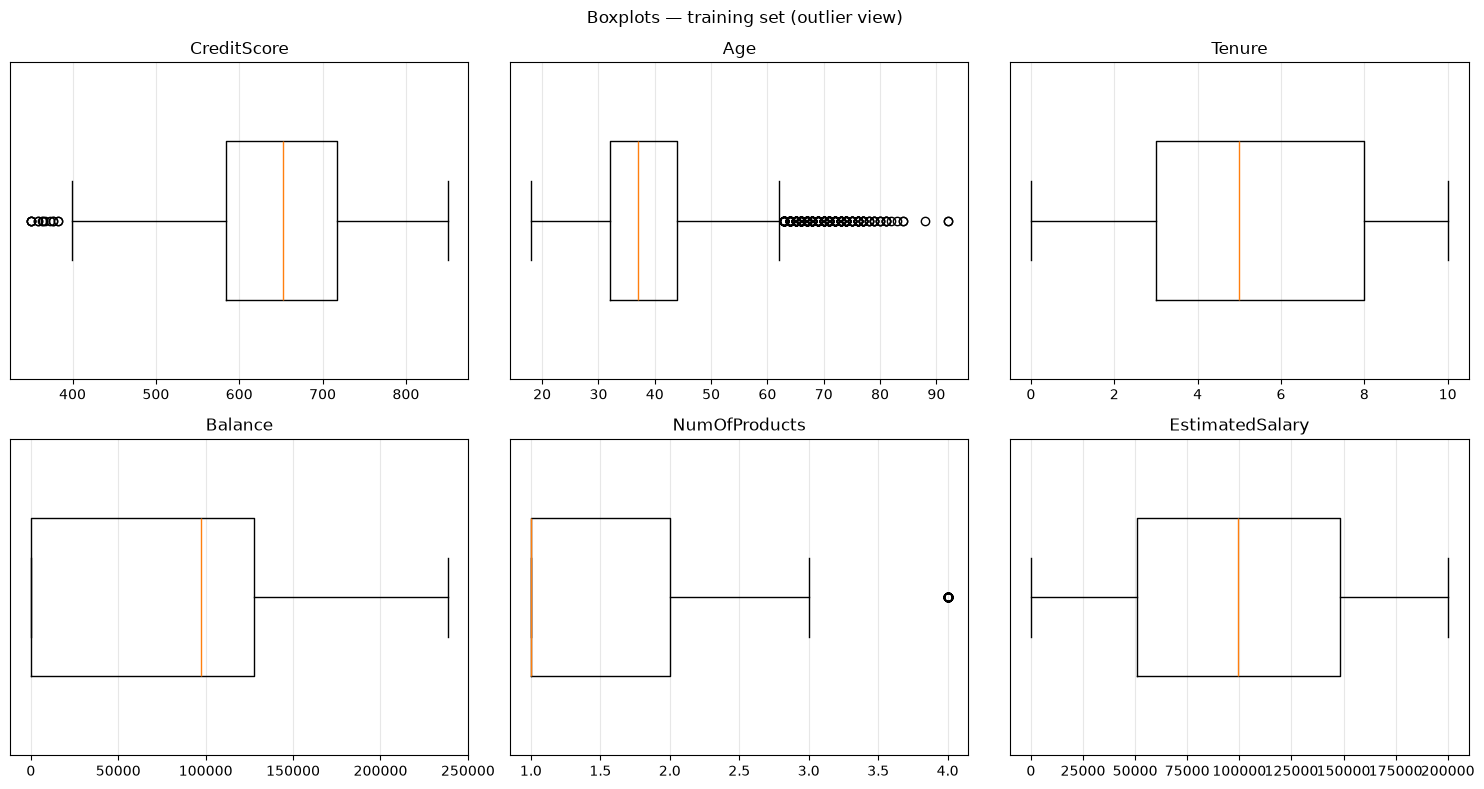

In [58]:
section("2.2 OUTLIERS (train set)")
desc = train[NUMERIC_COLS].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T.round(2)
desc["skew"] = train[NUMERIC_COLS].skew().round(2)
desc["kurtosis"] = train[NUMERIC_COLS].kurt().round(2)
display(desc)

rows = []
for col in NUMERIC_COLS:
    s = train[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_out = int(((s < low) | (s > high)).sum())
    z_out = int(((s - s.mean()) / s.std()).abs().gt(3).sum())
    rows.append({
        "lower_fence": round(low, 2),
        "upper_fence": round(high, 2),
        "iqr_outliers": iqr_out,
        "iqr_%": round(iqr_out / len(s) * 100, 2),
        "z>3_outliers": z_out,
        "z>3_%": round(z_out / len(s) * 100, 2),
    })

outliers = pd.DataFrame(rows, index=pd.Index(NUMERIC_COLS, name="feature"))
print("\nIQR (1.5x) and z-score (>3) outlier counts:")
print(outliers)
print(f"\ntotal IQR-flagged values: {outliers['iqr_outliers'].sum():,} "
      f"({outliers['iqr_outliers'].sum() / (len(train) * len(NUMERIC_COLS)):.2%} of numeric cells)")

zero_balance = (train["Balance"] == 0).mean()
print(f"Balance == 0: {(train['Balance'] == 0).sum():,} train customers ({zero_balance:.1%}) "
      "-> real zero-balance accounts, not corrupt rows")
print("outliers are plausible values (high salary, high balance, age 70+) -> "
      "keep them and let the models cope (trees are robust; use RobustScaler/quantile bins if scaling)")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), NUMERIC_COLS):
    ax.boxplot(train[col].dropna(), orientation="horizontal", widths=0.5)
    ax.set_title(col)
    ax.set_yticks([])
    ax.grid(alpha=0.3, axis="x")
fig.suptitle("Boxplots — training set (outlier view)")
plt.tight_layout()
plt.show()

### 2.3 Categorical frequency mapping

In [59]:
section("2.3 CATEGORICAL FREQUENCIES (train set)")
for col in ["Geography", "Gender"]:
    counts= train[col].value_counts()
    freq = pd.DataFrame({
        "count": counts,
        "share_%": (counts / len(train) * 100).round(2),
        "cum_share_%": (counts.cumsum() / len(train) * 100).round(2),
        "churn_rate_%": (train.groupby(col)[TARGET].mean() * 100).round(2).reindex(counts.index),
    })
    label = f"{col}: {train[col].nunique()} distinct values"
    if train[col].nunique() > 10:
        label += " (top 10 shown)"
    print(f"--- {label}")
    print(freq.head(10) if train[col].nunique() > 10 else freq)
    print()


2.3 CATEGORICAL FREQUENCIES (train set)
--- Geography: 3 distinct values
           count  share_%  cum_share_%  churn_rate_%
Geography                                           
France      3993    49.91        49.91         15.90
Germany     2005    25.06        74.98         33.07
Spain       2002    25.02       100.00         16.58

--- Gender: 2 distinct values
        count  share_%  cum_share_%  churn_rate_%
Gender                                           
Male     4387    54.84        54.84         16.50
Female   3613    45.16       100.00         25.08



### 2.4 Numerical distributions


2.4 NUMERICAL DISTRIBUTIONS (train set)


,mean,median,std,min,max,skew,zeros_%
CreditScore,650.75,652.00,96.60,350.00,850.00,-0.08,0.00
Age,38.95,37.00,10.53,18.00,92.00,1.04,0.00
Tenure,5.02,5.00,2.90,0.00,10.00,0.01,4.19
Balance,"76,381.21","97,055.14","62,302.05",0.00,"238,387.56",-0.14,36.14
NumOfProducts,1.53,1.00,0.58,1.00,4.00,0.76,0.00
EstimatedSalary,"99,730.81","99,446.94","57,335.12",11.58,"199,992.48",0.01,0.00


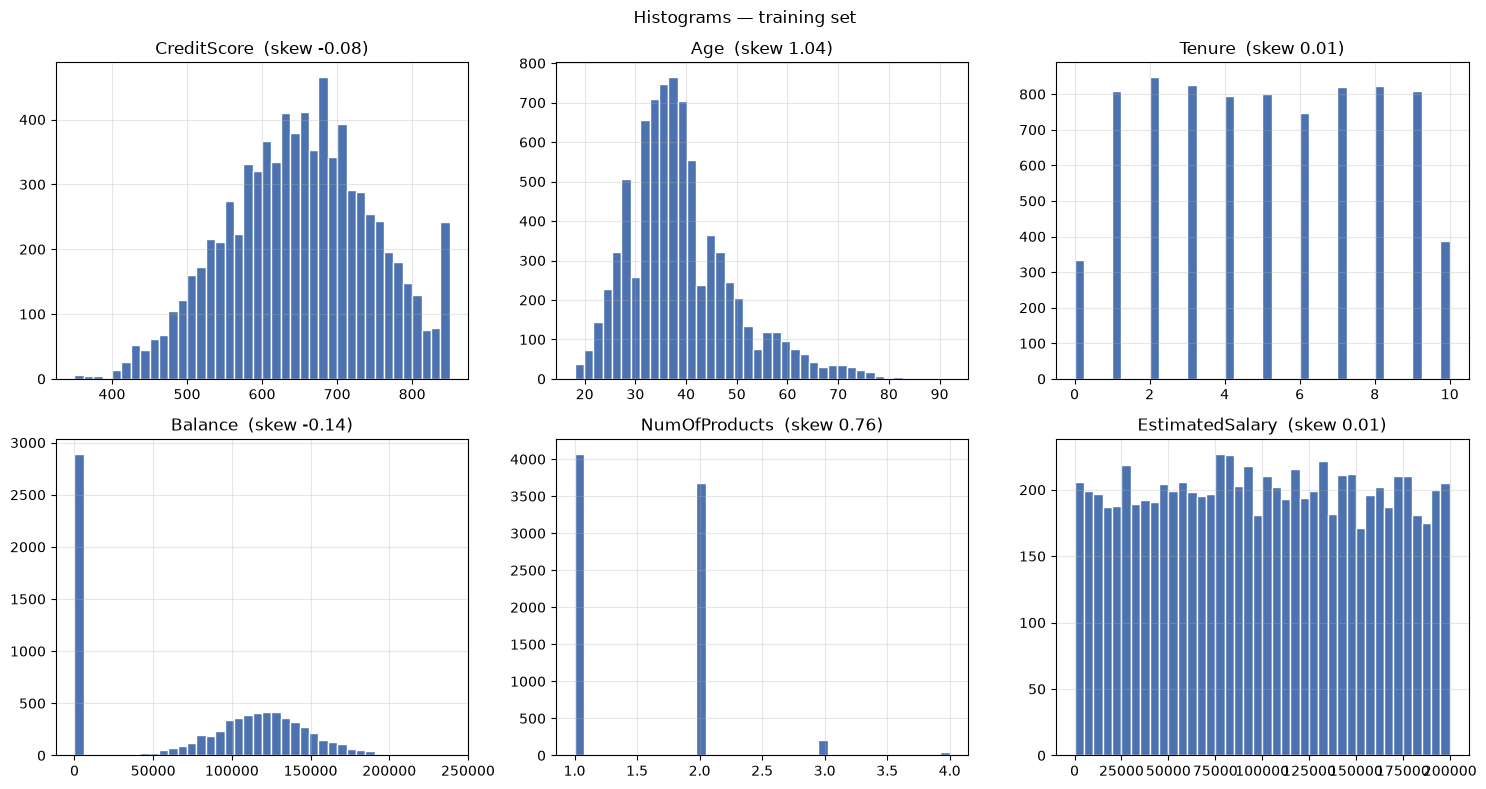

In [60]:
section("2.4 NUMERICAL DISTRIBUTIONS (train set)")
dist = pd.DataFrame({
    "mean": train[NUMERIC_COLS].mean(),
    "median": train[NUMERIC_COLS].median(),
    "std": train[NUMERIC_COLS].std(),
    "min": train[NUMERIC_COLS].min(),
    "max": train[NUMERIC_COLS].max(),
    "skew": train[NUMERIC_COLS].skew(),
    "zeros_%": (train[NUMERIC_COLS] == 0).mean().mul(100),
}).round(2)
display(dist)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), NUMERIC_COLS):
    ax.hist(train[col], bins=40, color="#4C72B0", edgecolor="white")
    ax.set_title(f"{col}  (skew {train[col].skew():.2f})")
    ax.grid(alpha=0.3)
fig.suptitle("Histograms — training set")
plt.tight_layout()
plt.show()

### 2.5 Numerical distributions split by churn


2.5 NUMERIC FEATURES vs CHURN (train set)
                 stayed (0)  churned (1)  diff_%
CreditScore          652.41       644.26   -1.20
Age                   37.45        44.78   19.60
Tenure                 5.02         5.00   -0.30
Balance           72,554.14    91,337.28   25.90
NumOfProducts          1.55         1.47   -5.10
EstimatedSalary   99,143.25   102,026.98    2.90


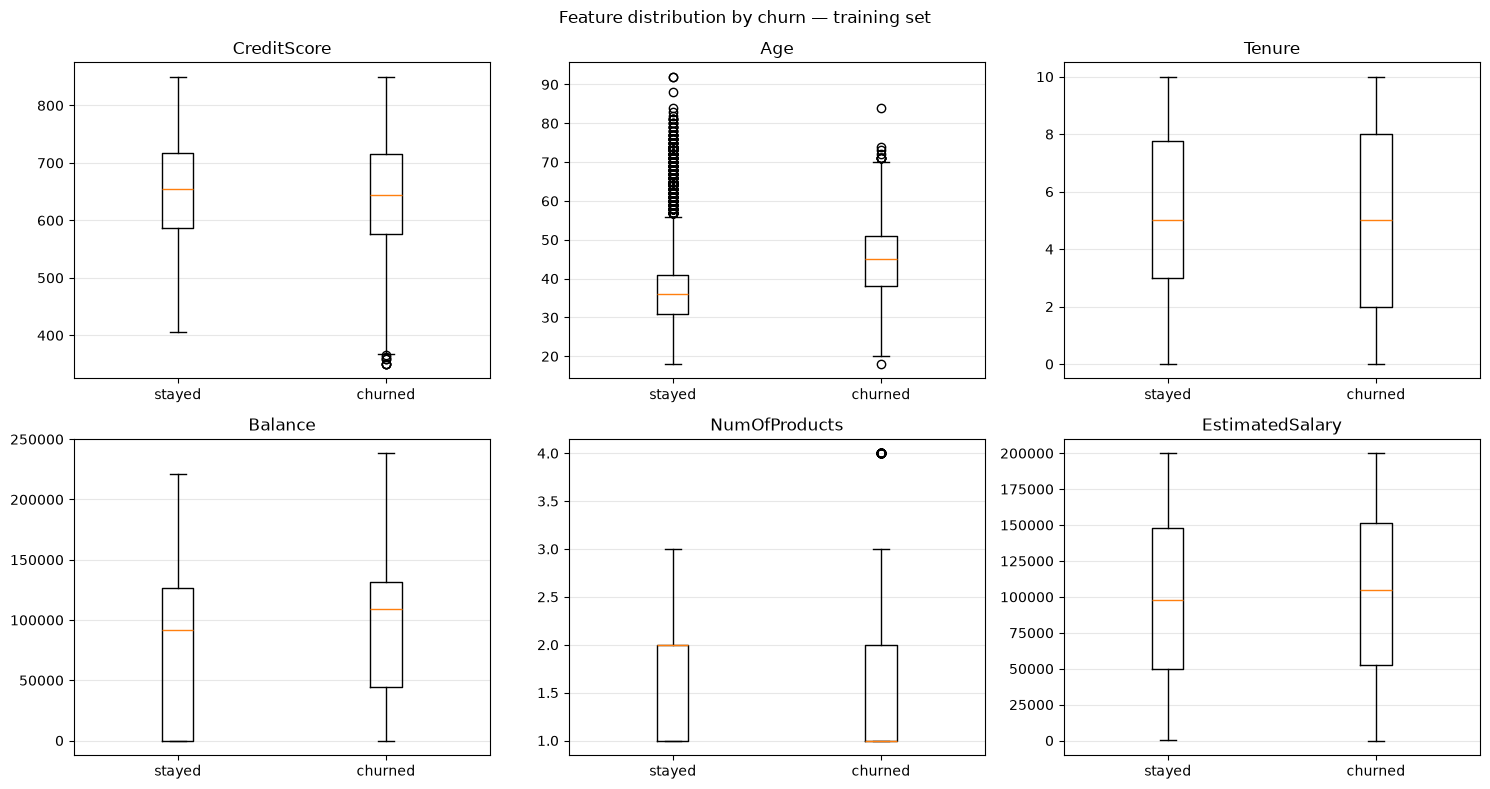

In [61]:
section("2.5 NUMERIC FEATURES vs CHURN (train set)")
by_target = train.groupby(TARGET)[NUMERIC_COLS].mean().T
by_target.columns = ["stayed (0)", "churned (1)"]
by_target["diff_%"] = ((by_target["churned (1)"] - by_target["stayed (0)"])
                       / by_target["stayed (0)"] * 100).round(1)
print(by_target.round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), NUMERIC_COLS):
    ax.boxplot([train.loc[train[TARGET] == 0, col], train.loc[train[TARGET] == 1, col]])
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["stayed", "churned"])
    ax.set_title(col)
    ax.grid(alpha=0.3, axis="y")
fig.suptitle("Feature distribution by churn — training set")
plt.tight_layout()
plt.show()

### 2.6 EDA summary

In [62]:
section("2.6 SUMMARY (training set)")
print(f"- {len(train):,} train rows / {len(test):,} test rows, churn {train[TARGET].mean():.2%} in both")
print(f"- missing values: {int(df.isna().sum().sum())} | exact duplicates: {int(df.duplicated().sum())}")
print("- dropped identifiers: " + ", ".join(DROP_COLS))
print(f"- IQR outliers: {int(outliers['iqr_outliers'].sum()):,} values "
      f"(mostly Age and CreditScore tails); keep them, they are plausible customers")
print(f"- Balance == 0 for {zero_balance:.1%} of customers -> add an is_zero_balance flag")
print("- categorical signal: Geography (Germany churns hardest), Gender (female higher)")
print("- strongest numeric split seen: Age (churners noticeably older), then Balance/NumOfProducts")
print("- next: encode Geography/Gender, then train an imbalanced-aware classifier "
      "(class_weight / scale_pos_weight) and evaluate with ROC-AUC, PR-AUC, recall")


2.6 SUMMARY (training set)
- 8,000 train rows / 2,000 test rows, churn 20.38% in both
- missing values: 0 | exact duplicates: 0
- dropped identifiers: RowNumber, CustomerId, Surname
- IQR outliers: 362 values (mostly Age and CreditScore tails); keep them, they are plausible customers
- Balance == 0 for 36.1% of customers -> add an is_zero_balance flag
- categorical signal: Geography (Germany churns hardest), Gender (female higher)
- strongest numeric split seen: Age (churners noticeably older), then Balance/NumOfProducts
- next: encode Geography/Gender, then train an imbalanced-aware classifier (class_weight / scale_pos_weight) and evaluate with ROC-AUC, PR-AUC, recall
